# Celkernen met de hand verbeteren

Cellpose vindt de celkernen op een foto automatisch, maar zit er soms naast. Het mist een kern, ziet twee kernen als één, of denkt dat een vlekje een kern is. Met dit notebook kun je die fouten zelf met de muis verbeteren.

## Snel aan de slag

**Wat stop je erin?** Maak een map `data` **naast dit notebook** en zet daar je foto's in (`.jpg`, `.png` of `.tif`):
```
jouw map/
├── masks_corrigeren.ipynb
└── data/
    ├── foto1.jpg
    └── foto2.jpg
```
Alleen **blauwe** foto's (kernkleuring, Hoechst/DAPI) worden gebruikt. Andere foto's worden vanzelf overgeslagen.

**Stappen**
1. Eenmalig: installeer de pakketten (zie **stap 0** hieronder).
2. Draai het notebook (*Run All*). Cellpose zoekt dan de kernen op elke blauwe foto en zet alles klaar in `output/handmatig/`.
3. Open het Cellpose-programma (**stap 3**), sleep een `.tif` uit `output/handmatig/` erin en verbeter de kernen. Opslaan doe je met Cmd + S (Mac) of Ctrl + S (Windows).
4. Draai **stap 4 en 5** opnieuw. Je verbeterde versie wordt opgeslagen en je ziet wat er veranderd is.

**Wat krijg je eruit?** Alles komt in de map `output/`, die het notebook zelf aanmaakt:
```
output/
├── masks/                 <- wat Cellpose automatisch vond (niet aanpassen)
├── handmatig/             <- hier werk je in: per foto een .tif + _seg.npy
└── masks_gecorrigeerd/    <- EINDRESULTAAT: jouw verbeterde kernen, één .npy per foto
```
Wat je met het eindresultaat kunt doen, staat in **stap 6**.

Draai je het notebook later opnieuw, dan worden foto's die je al verbeterd hebt **niet** overschreven. Nieuwe foto's in `data/` worden er gewoon bij gedaan.

---

## 0. Installeren (eenmalig)

Je kunt elke Python-omgeving gebruiken (Python 3.10 of nieuwer), zolang deze pakketten erin zitten:

| Pakket | Waarvoor |
|---|---|
| `cellpose[gui]` | Cellpose zelf + het programma waarin je met de muis werkt (~250 MB) |
| `scikit-image` | foto's inlezen en bewerken |
| `numpy` | rekenen met de maskers (komt mee met cellpose) |
| `matplotlib` | de voor-en-na plaatjes |
| `pandas` | de telling als tabel en .csv |
| `ipykernel` | om het notebook in Jupyter of VS Code te draaien |

In ons project gebruiken we de conda-omgeving **`ai-s4`**. Heb je een andere omgeving, vervang `ai-s4` hieronder dan door de naam van jouw omgeving.

**Mac**: open *Terminal*. **Windows**: open *Anaconda Prompt* (via het Startmenu). Typ dan:
```
conda activate ai-s4
pip install "cellpose[gui]" scikit-image matplotlib pandas ipykernel
```
Pakketten die je al hebt, worden overgeslagen.

**Controleren of het gelukt is:**
```
python -c "import cellpose.gui.gui, skimage, matplotlib, pandas; print('gelukt')"
```
Zie je `gelukt`, dan ben je klaar. Kies in Jupyter of VS Code rechtsboven dezelfde omgeving als kernel.

**Windows met een NVIDIA-videokaart: GPU aanzetten**

Op Windows installeert `pip` standaard een PyTorch die alleen op de processor (CPU) draait. Cellpose werkt dan wel, maar veel langzamer. Heb je een NVIDIA-videokaart, vervang PyTorch dan door de versie met CUDA (in dezelfde *Anaconda Prompt*, ~2,5 GB):
```
pip uninstall -y torch
pip install torch --index-url https://download.pytorch.org/whl/cu126
```
Controleren:
```
python -c "import torch; print(torch.cuda.is_available())"
```
Zie je `True`, dan gebruikt Cellpose de videokaart. Zie je `False`, update dan je NVIDIA-driver en probeer het opnieuw. Op een Mac hoef je niks te doen: daar gebruikt Cellpose de GPU (MPS) vanzelf. Heb je geen NVIDIA-kaart (bijv. Intel of AMD), dan draait het altijd op de processor.

Wat het notebook echt gebruikt, zie je bovenaan de uitvoer van **stap 2**: daar staat `Cellpose draait op: ...`.

<details>
<summary><b>Nog geen omgeving?</b> Klik hier.</summary>

Maak er een aan (de naam `ai-s4` mag je zelf kiezen):
```
conda create -n ai-s4 python=3.12 -y
conda activate ai-s4
pip install "cellpose[gui]" scikit-image matplotlib pandas ipykernel
python -m ipykernel install --user --name ai-s4 --display-name ai-s4
```
Geen conda? Een gewone `venv` werkt ook: maak die aan, activeer hem en voer dezelfde `pip install`-regel uit.
</details>

Let op: de eerste keer dat Cellpose kernen zoekt, downloadt het nog het model (~1,2 GB). Daarna staat het op je computer.

## 1. Instellingen
Hier staat welke mappen gebruikt worden. Meestal hoef je hier niks te veranderen.

In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"   # voorkomt een 'OMP: Error #15'-crash; moet vóór cellpose/torch staan

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from skimage import io, exposure, segmentation
from cellpose import utils

DATA_DIR   = Path("data")                      # map met de originele foto's
MASK_DIR   = Path("output/masks")              # kernen die Cellpose vond (zelfde map als kernen_labelen.ipynb)
EDIT_DIR   = Path("output/handmatig")          # hier werk je in het Cellpose-programma
FIXED_DIR  = Path("output/masks_gecorrigeerd") # jouw verbeterde kernen komen hier

DOWNSCALE   = 2    # foto's half zo groot maken: ~4x sneller, bijna hetzelfde resultaat
MIN_AREA_PX = 60   # vlakjes kleiner dan dit zijn waarschijnlijk vuil

DATA_DIR.mkdir(exist_ok=True)
for d in (MASK_DIR, EDIT_DIR, FIXED_DIR):
    d.mkdir(parents=True, exist_ok=True)

## 2. Kernen zoeken en klaarzetten

Dit stuk doet per blauwe foto in `data/`:
1. **Kernen zoeken.** Heeft Cellpose deze foto al gedaan (bijv. via `kernen_labelen.ipynb`), dan wordt dat resultaat gebruikt. Anders zoekt Cellpose de kernen nu. Dat duurt per foto ongeveer een halve minuut.
2. **Klaarzetten** in `output/handmatig/`:
   - een `.tif`: de foto zoals Cellpose hem zag (alleen blauw, wat feller en half zo groot)
   - een `_seg.npy`: de kernen die Cellpose vond

Heb je een foto al verbeterd, dan blijft die zoals hij is. Je werk raakt dus niet kwijt als je dit opnieuw draait. Wil je toch opnieuw beginnen, gooi dan het `_seg.npy`-bestand van die foto weg.

In [2]:
def is_blauw(img):
    return img.ndim == 3 and img[..., 2].mean() > img[..., 0].mean() and img[..., 2].mean() > img[..., 1].mean()

def preprocess(img):
    blue = img[..., 2].astype(np.float32)
    lo, hi = np.percentile(blue, [1, 99.8])
    norm = exposure.rescale_intensity(blue, in_range=(lo, hi), out_range=(0, 1))
    return norm[::DOWNSCALE, ::DOWNSCALE] if DOWNSCALE > 1 else norm

from cellpose import core
APPARAAT, _ = core.assign_device(gpu=True)          # CUDA als die werkt, anders Mac-GPU (MPS), anders de processor
namen = {"cuda": "NVIDIA-videokaart (CUDA)", "mps": "Mac-GPU (MPS)"}
print("Cellpose draait op:", namen.get(APPARAAT.type, "processor (CPU). Dit is trager, zie stap 0 om de GPU aan te zetten"))

model = None
def zoek_kernen(small):
    global model
    if model is None:                               # model pas laden als het echt nodig is
        from cellpose import models
        model = models.CellposeModel(device=APPARAAT)
    masks, _, _ = model.eval(small, batch_size=8)
    te_klein = np.bincount(masks.ravel()) < MIN_AREA_PX   # vlakjes kleiner dan MIN_AREA_PX weghalen
    te_klein[0] = False
    masks[te_klein[masks]] = 0
    masks, _, _ = segmentation.relabel_sequential(masks)
    return masks

fotos = sorted(p for p in DATA_DIR.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".tif", ".tiff"})
if not fotos:
    raise FileNotFoundError(f"Geen foto's gevonden in '{DATA_DIR.resolve()}'. Zet je foto's in een map 'data' naast dit notebook.")
for foto in fotos:
    naam = foto.stem
    seg_pad = EDIT_DIR / f"{naam}_seg.npy"
    if seg_pad.exists():
        print(f"al klaargezet       {naam}")
        continue
    img = io.imread(foto)
    if not is_blauw(img[..., :3] if img.ndim == 3 else img):
        print(f"overslaan (niet blauw)  {naam}")
        continue
    small = preprocess(img[..., :3])
    mask_pad = MASK_DIR / f"{naam}.npy"
    if mask_pad.exists():
        masks = np.load(mask_pad)
    else:
        print(f"kernen zoeken...    {naam}")
        masks = zoek_kernen(small)
        np.save(mask_pad, masks)
    small_u8 = (small * 255).astype(np.uint8)
    assert small_u8.shape == masks.shape, (small_u8.shape, masks.shape)
    beeld_pad = EDIT_DIR / f"{naam}.tif"
    io.imsave(beeld_pad, small_u8, check_contrast=False)
    np.save(seg_pad, {
        "masks": masks.astype(np.uint16),
        "outlines": utils.masks_to_outlines(masks).astype(np.uint16) * masks.astype(np.uint16),
        "filename": str(beeld_pad.resolve()),
        "img": small_u8,
        "ismanual": np.zeros(masks.max(), bool),
    })
    print(f"klaargezet          {naam:20s} {masks.max():4d} kernen")

kernen zoeken...    100
klaargezet          100                   129 kernen
kernen zoeken...    11
klaargezet          11                    118 kernen
kernen zoeken...    12
klaargezet          12                     95 kernen
kernen zoeken...    13
klaargezet          13                    125 kernen
kernen zoeken...    14
klaargezet          14                    109 kernen


## 3. Verbeteren in het Cellpose-programma

### Programma openen
**Mac** (Terminal):
```
conda activate ai-s4
KMP_DUPLICATE_LIB_OK=TRUE python -m cellpose
```
**Windows** (Anaconda Prompt):
```
conda activate ai-s4
set KMP_DUPLICATE_LIB_OK=TRUE
python -m cellpose
```
Gebruik je een andere omgeving dan `ai-s4`, vervang dan die naam. `KMP_DUPLICATE_LIB_OK` voorkomt dat het programma meteen afsluit met een `OMP`-foutmelding.

Het venster dat opengaat is eerst **leeg**. Sleep een `.tif` uit `output/handmatig/` naar het zwarte vlak, of druk op **Cmd + L** (Mac) / **Ctrl + L** (Windows) en kies de `.tif`. Neem de `.tif` en niet het `_seg.npy`-bestand, want dat laadt vanzelf mee.

### Wat zie je?
- **Elk gekleurd vlakje is één kern** die Cellpose gevonden heeft. De kleuren betekenen verder niks. Ze zijn willekeurig gekozen, zodat je kernen die tegen elkaar aan liggen uit elkaar kunt houden.
- **ROIs** (links, bijv. *311 ROIs*) is het aantal gevonden kernen. ROI is het vakwoord voor "gevonden object". Het getal verandert als jij kernen toevoegt of weghaalt.

### Bediening
| Wat | Mac | Windows |
|---|---|---|
| Inzoomen | twee vingers schuiven op trackpad / scrollwiel | scrollwiel |
| Verschuiven | klikken en slepen | klikken en slepen |
| Hele foto weer zien | dubbelklikken | dubbelklikken |
| Foute kern **weghalen** | **⌘ Cmd** + klik op de kern | **Ctrl** + klik op de kern |
| Twee stukken **samenvoegen** | **⌥ Option** + klik op beide stukken | **Alt** + klik op beide stukken |
| Gemiste kern **toevoegen** | rechtsklik (trackpad: klik met twee vingers) of **Shift + klik** | rechtsklik of **Shift + klik** |
| Eén kern **opsplitsen** | weghalen en de twee kernen apart opnieuw tekenen | idem |
| Terugdraaien | **⌘ Cmd + Z** | **Ctrl + Z** |
| **Opslaan** | **⌘ Cmd + S** | **Ctrl + S** |

**Een kern tekenen:** start met rechtsklik of Shift + klik, beweeg de muis om de kern heen (knop **niet** ingedrukt houden) en kom terug bij het rondje waar je begon. Dan sluit de vorm vanzelf.

Op de **Mac** klik je **niet met Ctrl**. Daar doet Ctrl iets anders dan Cmd.

### Welke knoppen heb je nodig?
**Handig** (blok *Drawing*)
- **MASKS ON [X]**: gekleurde vlakken aan/uit, zodat je ziet of er echt een kern onder zit. Kan ook met toets **X**.
- **outlines on [Z]**: dun randje om elke kern. Kan ook met toets **Z**.
- **delete multiple ROIs**: veel kernen tegelijk weghalen.
  - *click-select*: kernen aanklikken, dan **done**
  - *region-select*: vak over een stuk van de foto trekken, dan **done**
  - **cancel**: stoppen zonder iets weg te halen

**Niet aankomen**
- **run** (blok *Segmentation*): Cellpose zoekt dan alles opnieuw en je verbeteringen zijn weg.
- **user-trained models** en **Image filtering**: voor gevorderd gebruik, niet nodig.
- **Views** (bovenaan): verandert alleen hoe de foto eruitziet. Kan geen kwaad, maar is niet nodig.
- **brush size** en **single stroke**: laten zoals ze staan.

### Opslaan
- Na het **tekenen** van een kern slaat het programma zelf op.
- Na **weghalen** of **samenvoegen** niet, dus druk dan zelf op opslaan (Cmd + S / Ctrl + S).
- Het bestand komt in `output/handmatig/` als `<naam>_seg.npy`.

### Tips
- Zoom flink in en loop de foto stukje voor stukje door.
- Let vooral op: kernen zonder kleur (gemist), vlakjes zonder kern eronder (vuil) en grote vlakken die eigenlijk twee kernen zijn.
- Klaar met alle foto's? Draai dan stap 4 en 5 hieronder.

## 4. Verbeterde versie ophalen

Draai dit stuk als je klaar bent in het programma. Het haalt jouw verbeterde kernen op, bewaart ze in `output/masks_gecorrigeerd/` en laat zien hoeveel kernen er per foto bij zijn gekomen of afgegaan.

In [10]:
for seg_pad in sorted(EDIT_DIR.glob("*_seg.npy")):
    naam = seg_pad.name[:-len("_seg.npy")]
    dat = np.load(seg_pad, allow_pickle=True).item()
    nieuw = np.asarray(dat["masks"]).squeeze().astype(np.int32)
    nieuw, _, _ = segmentation.relabel_sequential(nieuw)
    np.save(FIXED_DIR / f"{naam}.npy", nieuw)
    oud = np.load(MASK_DIR / f"{naam}.npy")
    print(f"{naam:20s} Cellpose {oud.max():4d}  ->  na correctie {nieuw.max():4d}  ({nieuw.max() - oud.max():+d})")

100                  Cellpose  129  ->  na correctie  129  (+0)
11                   Cellpose  118  ->  na correctie  119  (+1)
12                   Cellpose   95  ->  na correctie   95  (+0)
13                   Cellpose  125  ->  na correctie  125  (+0)
14                   Cellpose  109  ->  na correctie  109  (+0)


## 5. Voor en na
Groen is de rand van elke kern na jouw verbetering. Rood laat zien waar je iets hebt veranderd.

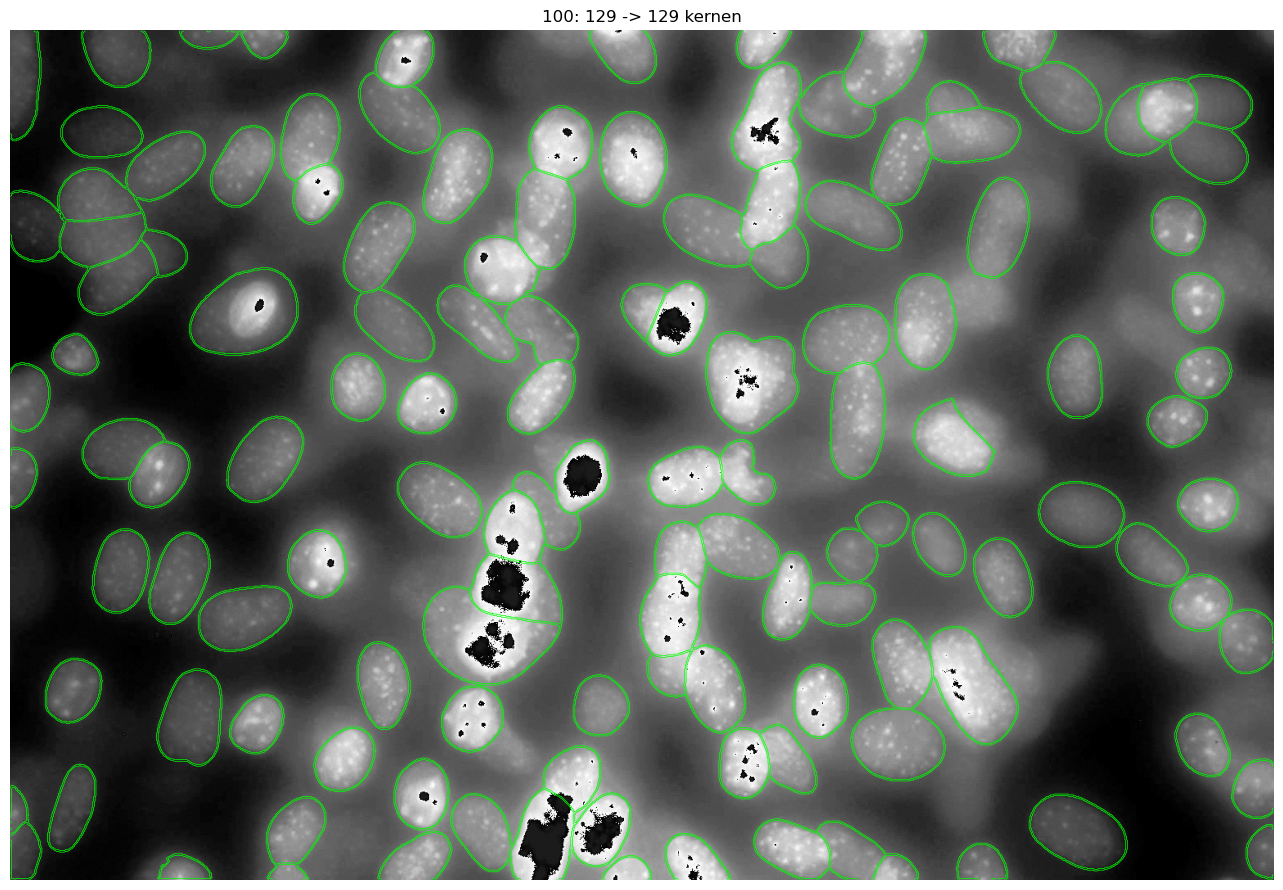

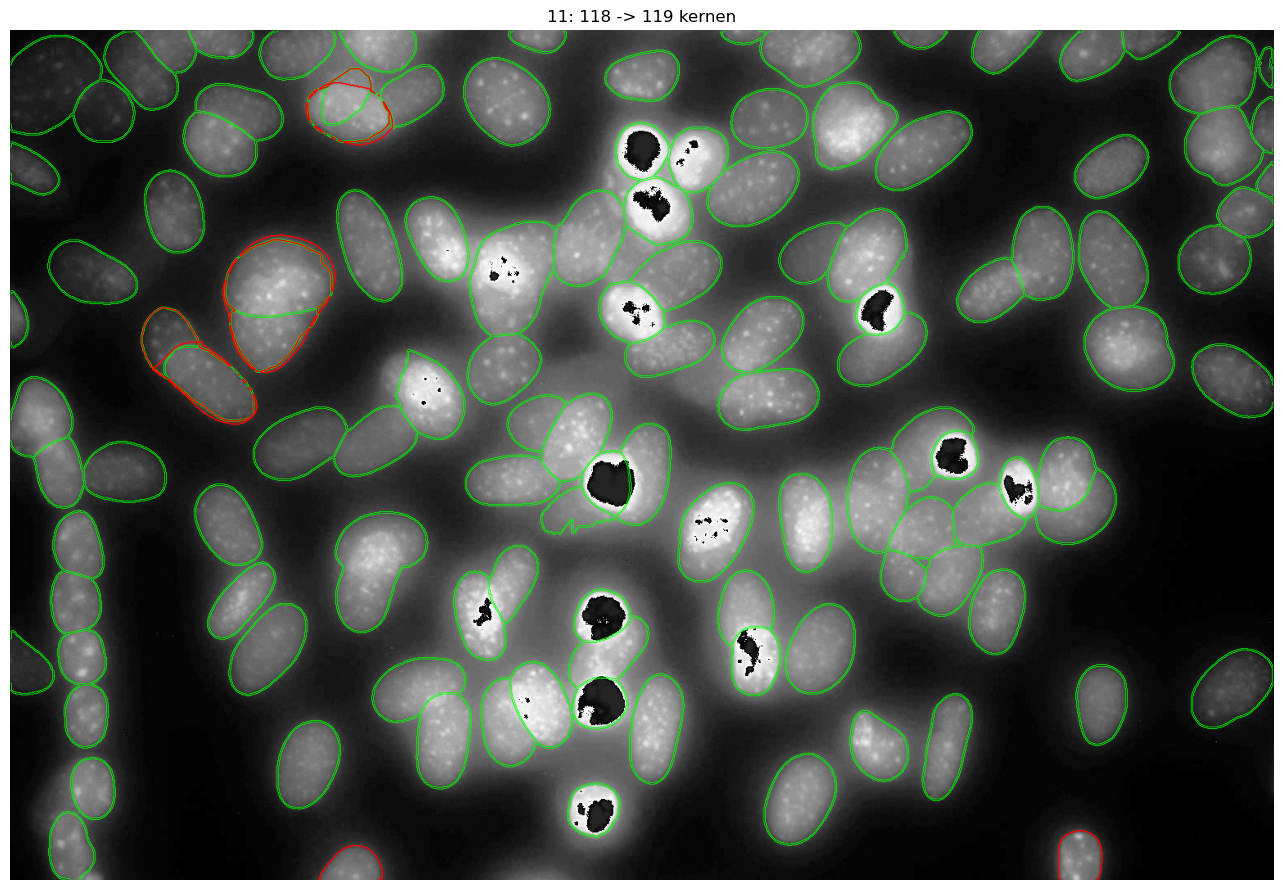

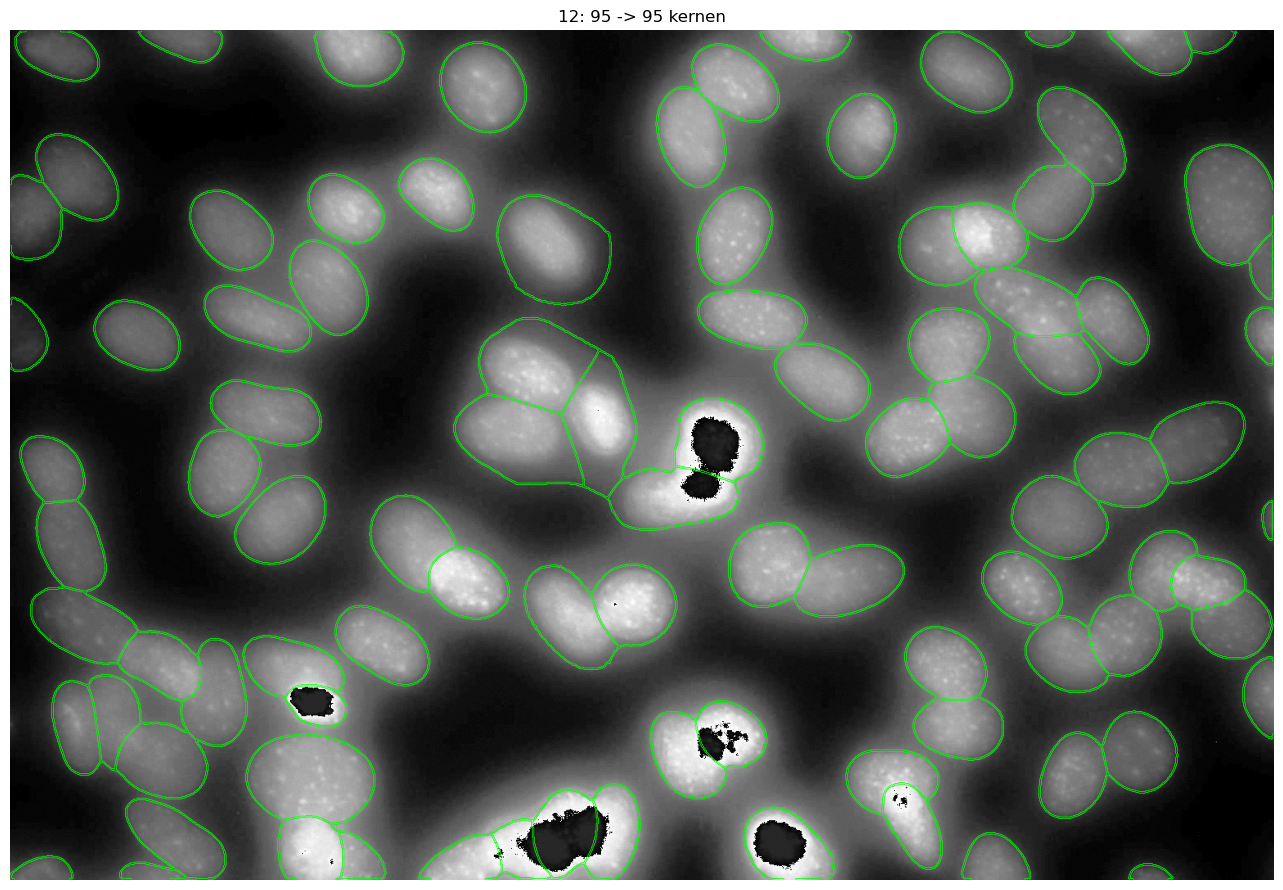

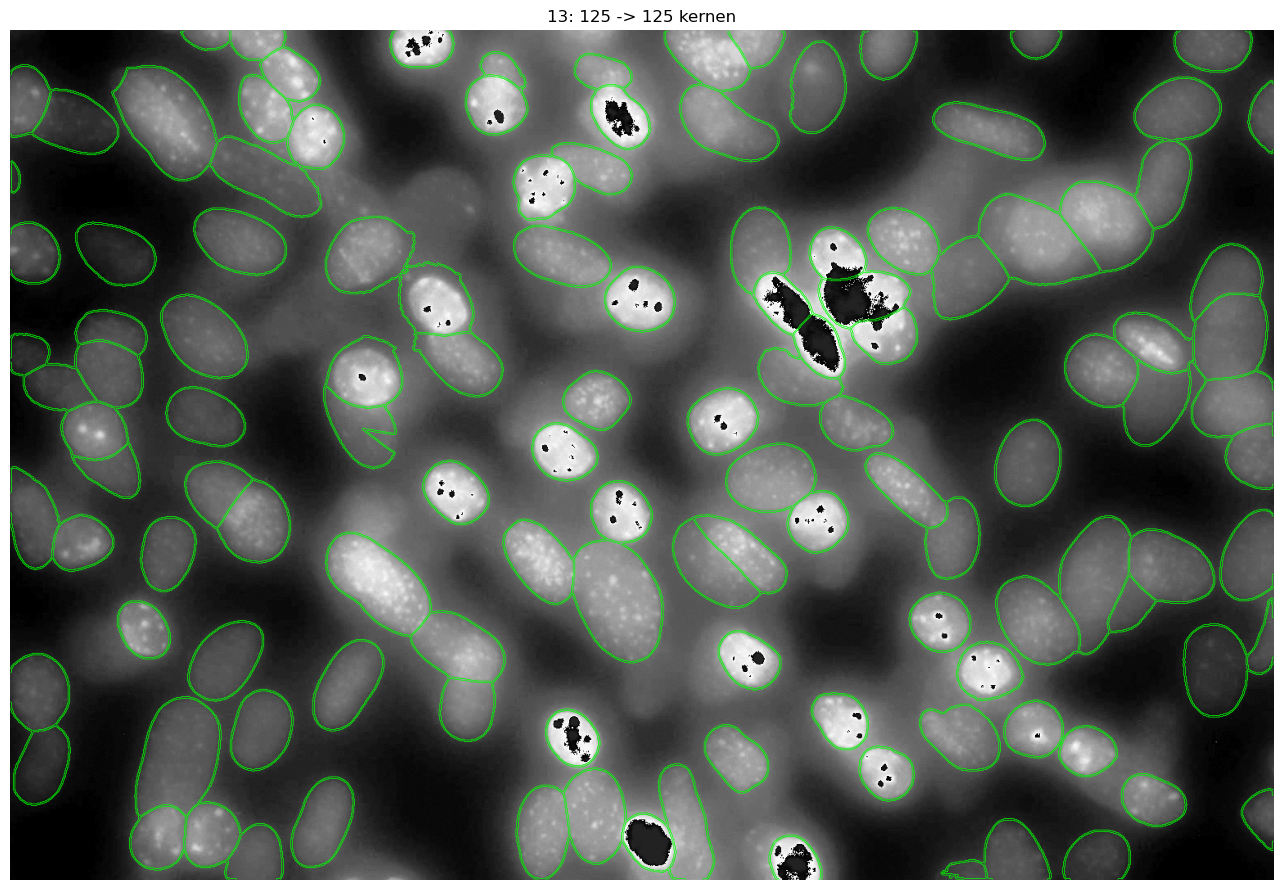

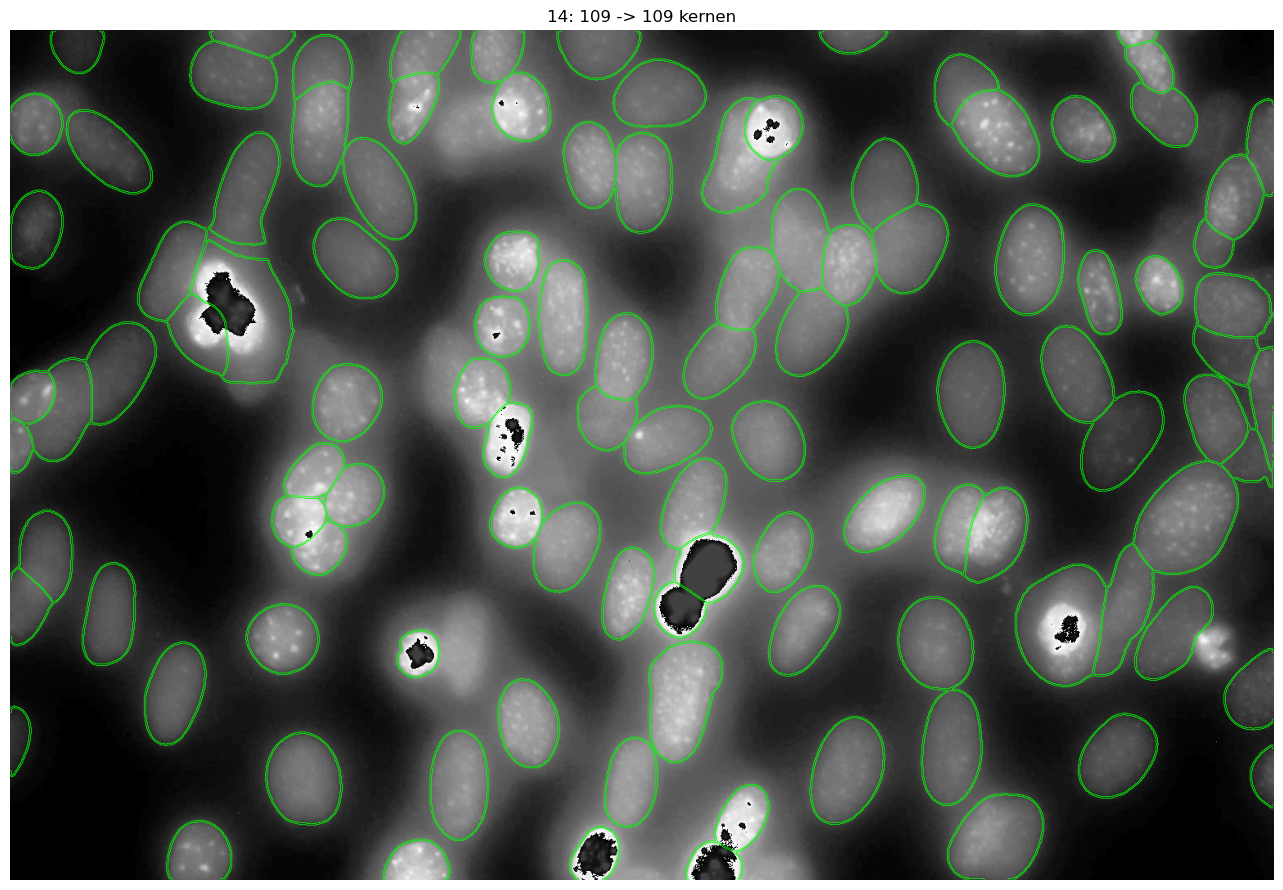

In [11]:
for pad in sorted(FIXED_DIR.glob("*.npy")):
    naam = pad.stem
    nieuw, oud = np.load(pad), np.load(MASK_DIR / pad.name)
    achtergrond = io.imread(EDIT_DIR / f"{naam}.tif")
    veranderd = (oud > 0) != (nieuw > 0)
    fig, ax = plt.subplots(figsize=(14, 9))
    ax.imshow(achtergrond, cmap="gray")
    ax.contour(segmentation.find_boundaries(nieuw), [0.5], colors="lime", linewidths=0.5)
    ax.contour(veranderd, [0.5], colors="red", linewidths=0.9)
    ax.set_title(f"{naam}: {oud.max()} -> {nieuw.max()} kernen")
    ax.axis("off"); plt.tight_layout(); plt.show()

## 6. Wat kun je met het resultaat?

In `output/masks_gecorrigeerd/` staat per foto één `.npy`-bestand. Dat is een "kaart" van de foto waarin elke pixel een nummer heeft:
- **0** = achtergrond (geen kern)
- **1, 2, 3, …** = kern 1, kern 2, kern 3, …

Het hoogste nummer is dus het **aantal kernen**. Let op: de kaart is **half zo groot** als de originele foto (`DOWNSCALE = 2`). Eén pixel op de kaart is 2×2 = 4 pixels van de originele foto.

Wat je ermee kunt:
- **Kernen tellen** per foto. Zie de cel hieronder, die maakt er ook een `.csv` van (te openen in Excel).
- **Grootte en vorm meten** per kern, bijvoorbeeld met `protocol_cellpose_sam_analyse.ipynb`. Zet daar de regel `MASK_DIR = Path("output/masks_gecorrigeerd")`, dan rekent dat notebook met jouw verbeterde versie.
- **Vergelijken** met de automatische telling, om te zien hoe vaak Cellpose het fout had (stap 4 laat dat verschil al zien).
- **Cellpose bijtrainen** op jouw verbeteringen, zodat het de volgende keer minder fouten maakt. De `_seg.npy`-bestanden in `output/handmatig/` zijn daar precies het goede formaat voor.

In [5]:
import pandas as pd

rijen = []
for pad in sorted(FIXED_DIR.glob("*.npy")):
    kaart = np.load(pad)
    groottes = np.bincount(kaart.ravel())[1:] * DOWNSCALE**2      # oppervlak per kern, in pixels van de originele foto
    rijen.append({
        "foto": pad.stem,
        "kernen_cellpose": int(np.load(MASK_DIR / pad.name).max()),
        "kernen_na_correctie": int(kaart.max()),
        "gem_oppervlak_px": int(groottes.mean()) if len(groottes) else 0,
    })
telling = pd.DataFrame(rijen)
telling.to_csv("output/telling_gecorrigeerd.csv", index=False)
print("Opgeslagen: output/telling_gecorrigeerd.csv")
telling

Opgeslagen: output/telling_gecorrigeerd.csv


,foto,kernen_cellpose,kernen_na_correctie,gem_oppervlak_px
0,100,129,129,18830
1,11,118,118,20111
2,12,95,95,25314
3,13,125,125,19686
4,14,109,109,21622
